In [39]:
# Import Libraries

import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

In [40]:
# Load the dataset

flights = pd.read_csv("data/cleaned/analysis_ready_flights.csv")

In [41]:
# Create Dataset for Model 2

model2_cols = [
    "arr_delay",
    "season",
    "carrier",
    "scheduled_hour",
    "distance",
    "origin",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "pressure",
    "visib"

]


In [42]:
# Remove rows with missing values in the selected columns
missing_values = flights[model2_cols].isna().sum()

missing_percent = (
    flights[model2_cols].isna().mean() * 100
).round(2)

print("\nMissing Counts:")
print(missing_values)

print("\nMissing Percentages:")
print(missing_percent)

model2_data = flights[model2_cols].dropna()

# Check sample size after dropping missing values
print(f"\nSample size after dropping missing values: {len(model2_data):,}"
      f"of {len(flights):,} flights")

print(f"Excluded flights: "
      f"{len(flights) - len(model2_data):,} flights")


Missing Counts:
arr_delay             0
season                0
carrier               0
scheduled_hour        0
distance              0
origin                0
temp               1544
humid              1544
wind_speed         1605
precip             1527
pressure          36142
visib              1527
dtype: int64

Missing Percentages:
arr_delay          0.00
season             0.00
carrier            0.00
scheduled_hour     0.00
distance           0.00
origin             0.00
temp               0.47
humid              0.47
wind_speed         0.49
precip             0.47
pressure          11.04
visib              0.47
dtype: float64

Sample size after dropping missing values: 291,140of 327,346 flights
Excluded flights: 36,206 flights


After removing observations with missing data, 291,140 0f 327,346 flights remained, and a total of 36,206 flights were excluded. 

In [43]:
# Create Model 1 Comparison dataset from Model 2 sample

model1_comparison_data = model2_data[
    ['arr_delay', 'season', 'carrier', 'scheduled_hour', 'distance', 'origin']
].copy() 

In [44]:
# Check sample size after removing missing values
print(f"Sample size for Model 2: {len(model2_data)}")
print(f"Flights excluded:", len(flights) - len(model2_data))

Sample size for Model 2: 291140
Flights excluded: 36206


In [45]:
# Check for missing values in the selected columns

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
arr_delay             0
season                0
carrier               0
scheduled_hour        0
distance              0
origin                0
temp               1544
humid              1544
wind_speed         1605
precip             1527
pressure          36142
visib              1527
dtype: int64


In [46]:
# Summary statistics for weather variables

weather_summary = model2_data[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']].describe()

print("Summary statistics for weather variables:")
print(weather_summary)

Summary statistics for weather variables:
                temp          humid     wind_speed         precip  \
count  291140.000000  291140.000000  291140.000000  291140.000000   
mean       57.077140      56.148008      10.959332       0.001348   
std        18.079445      18.034573       5.484414       0.012589   
min        10.940000      12.740000       0.000000       0.000000   
25%        42.080000      42.320000       6.904680       0.000000   
50%        57.020000      54.350000      10.357020       0.000000   
75%        73.040000      69.320000      13.809360       0.000000   
max       100.040000     100.000000      39.126520       0.530000   

            pressure          visib  
count  291140.000000  291140.000000  
mean     1017.900041       9.587284  
std         7.419816       1.455421  
min       983.800000       0.000000  
25%      1012.900000      10.000000  
50%      1017.600000      10.000000  
75%      1022.900000      10.000000  
max      1042.100000      10.000

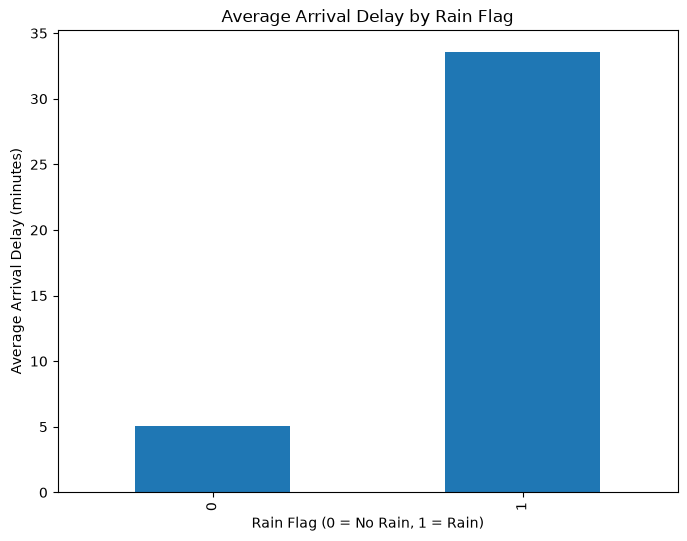

In [47]:
# Create a rain flag variable to indicate whether it rained or not

flights["rain_flag"] = (flights["precip"] > 0).astype(int)

# Calculate average arrival delay for flights with and without rain

rain_summary = flights.groupby("rain_flag").agg(
    avg_delay=("arr_delay", "mean")
)

# Create a bar chart

rain_summary.plot(
    kind="bar", legend=False, figsize=(8, 6), title="Average Arrival Delay by Rain Flag"
)

plt.title("Average Arrival Delay by Rain Flag")
plt.xlabel("Rain Flag (0 = No Rain, 1 = Rain)")
plt.ylabel("Average Arrival Delay (minutes)")
plt.show()

During periods of precipitation, flights had higher average arrival delays, sugguesting rain may contribute to longer delays and operational disruptions. This is a descriptive comparison, and therefore does not control for season, carrier, airport, distance, or departure time.

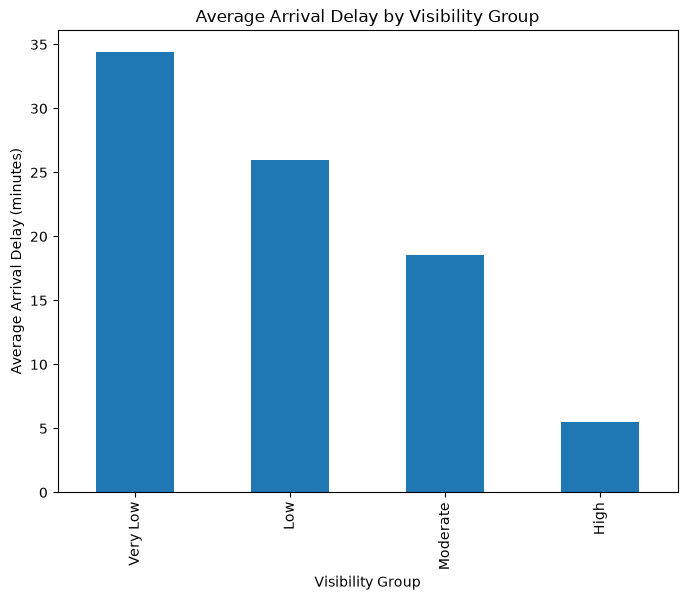

In [48]:

# Create a visibility group variable based on visibility ranges

flights["visibility_group"] = pd.cut(
    flights["visib"],
    bins=[-1, 1, 3, 5, 10, float("inf")],
    labels=["Very Low", "Low", "Moderate", "High", "Very High"]
)

# Calculate average arrival delay for each visibility group

visibility_summary = flights.groupby("visibility_group").agg(
    avg_delay=("arr_delay", "mean")
)

# Create a bar chart showing average arrival delay for each visibility group
visibility_summary.plot(
    kind="bar", legend=False, figsize=(8, 6)
)
plt.title("Average Arrival Delay by Visibility Group")
plt.xlabel("Visibility Group")
plt.ylabel("Average Arrival Delay (minutes)")
plt.show()  

Flights departing in lower visibility conditions generally expereince greater delays which sugguests reduced visibility may contribute to longer delays and operational challenges.

Correlations with Arrival Delay:
arr_delay     1.000000
humid         0.141397
precip        0.111281
wind_speed    0.064069
temp          0.033026
visib        -0.135536
Name: arr_delay, dtype: float64


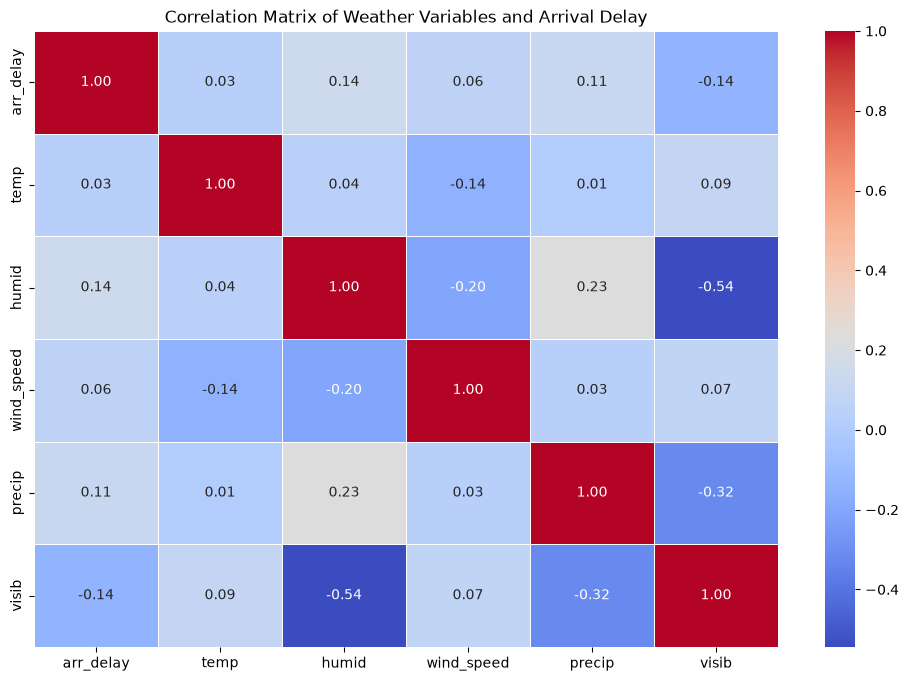

In [49]:
# Select weather-related variables for correlation analysis

weather_vars = [
    "arr_delay",
    "temp",
    "humid",
    "wind_speed",
    "precip",
    "visib"
]

# Calculate correlation matrix

correlation_matrix = flights[weather_vars].corr()

# Display correlations with arrival delay
print("Correlations with Arrival Delay:")
print(correlation_matrix['arr_delay'].sort_values(ascending=False))

# Create a heatmap to visualize the correlation matrix

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Matrix of Weather Variables and Arrival Delay")
plt.show()  

Most individual correlations are relatively weak, suggesting weather conditions may be more informative when collectively evaluated through a regression model as opposed to through pairwise relationships alone. 

No missing values remain win the variables used for model 2 after removing incomplete observations.

In [50]:
# Create reference categories for the 'season' variable

model2_data['season'] = pd.Categorical(
model2_data['season'], 
categories=['Winter', 'Spring', 'Summer', 'Fall']
)

# create Reference categories for the airline variable

model2_data['carrier'] = pd.Categorical(
    model2_data['carrier'], 
    categories=[
        "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
    ]   
)

# Create reference categories for the airport variable

model2_data['origin'] = pd.Categorical(
    model2_data['origin'], 
    categories=["JFK", "LGA", "EWR"]
)


In [51]:
# Create Dummy Variables for Categorical Variables

model2_data = pd.get_dummies(model2_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

# Check resulting dataset

print("Shape of the dataset after creating dummy variables:", model2_data.shape)
print(model2_data.head())

Shape of the dataset after creating dummy variables: (291140, 29)
   arr_delay  scheduled_hour  distance   temp  humid  wind_speed  precip  \
0       11.0               5      1400  39.02  64.43    12.65858     0.0   
1       20.0               5      1416  39.92  54.81    14.96014     0.0   
2       33.0               5      1089  39.02  61.63    14.96014     0.0   
3      -18.0               5      1576  39.02  61.63    14.96014     0.0   
4      -25.0               6       762  39.92  54.81    16.11092     0.0   

   pressure  visib  season_Spring  ...  carrier_MQ  carrier_OO  carrier_UA  \
0    1011.9   10.0              0  ...           0           0           1   
1    1011.4   10.0              0  ...           0           0           1   
2    1012.1   10.0              0  ...           0           0           0   
3    1012.1   10.0              0  ...           0           0           0   
4    1011.7   10.0              0  ...           0           0           0   

   carri

Dummy variables created for season, airline, and airport with the first category in each group serving as the reference category.

In [52]:
# create the independent variables (X) and dependent variable (y)

y_model2 = model2_data['arr_delay']
X_model2 = model2_data.drop('arr_delay', axis=1)

# create intercept for the regression model

X_model2=sm.add_constant(X_model2)

# Fit the regression model

model2_fit = sm.OLS(y_model2, X_model2).fit()

# Results

print(model2_fit.summary())


                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     899.9
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:56:01   Log-Likelihood:            -1.4889e+06
No. Observations:              291140   AIC:                         2.978e+06
Df Residuals:                  291111   BIC:                         2.978e+06
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            399.6132     11.682     34.

Model 2 adds weather variables including temperature, humidity, wind speed, precipitation, atmospheric pressure, and visibility. 

In [53]:
# Calculate Variance Inflation Factor (VIF) for each independent variable

vif_data = pd.DataFrame()
vif_data['Variable'] = X_model2.columns
vif_data['VIF'] = [variance_inflation_factor(X_model2.values, i) for i in range(X_model2.shape[1])]
print(vif_data.sort_values('VIF', ascending=False).reset_index(drop=True))


          Variable           VIF
0            const  24526.263450
1    season_Summer      4.470108
2             temp      3.075085
3       carrier_EV      2.958365
4       carrier_UA      2.880848
5       origin_EWR      2.688712
6       carrier_B6      2.482982
7      season_Fall      2.476548
8       carrier_DL      2.135081
9    season_Spring      2.043204
10      origin_LGA      1.994130
11      carrier_MQ      1.780191
12        distance      1.698729
13      carrier_9E      1.681012
14      carrier_US      1.632400
15           humid      1.555715
16           visib      1.479729
17      carrier_WN      1.395725
18      wind_speed      1.288700
19        pressure      1.250963
20      carrier_VX      1.208053
21          precip      1.160296
22      carrier_FL      1.114317
23  scheduled_hour      1.097478
24      carrier_HA      1.048606
25      carrier_AS      1.042619
26      carrier_F9      1.024614
27      carrier_YV      1.023336
28      carrier_OO      1.001382


To assess multicolinearity among the predictors variance inflation factors (VIF) were elevated sugguesting moderate multicollinearity

In [54]:
# Calculate heteroskedasticity-robust standard errors

model2_robust = model2_fit.get_robustcov_results(cov_type='HC3')

# Results

print(model2_robust.summary())

                            OLS Regression Results                            
Dep. Variable:              arr_delay   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     681.7
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        18:56:09   Log-Likelihood:            -1.4889e+06
No. Observations:              291140   AIC:                         2.978e+06
Df Residuals:                  291111   BIC:                         2.978e+06
Df Model:                          28                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            399.6132     11.876     33.

In [55]:
# test for heteroskedasticity using Breusch-Pagan test

# Add an intercept because X_model2 was not passed through sm.add_constant()
bp_exog = X_model2

bp_test = het_breuschpagan(model2_fit.resid, bp_exog)

print("LM Statistic:", bp_test[0])
print("p-value:", bp_test[1])

LM Statistic: 2859.5151829072943
p-value: 0.0


In [56]:
print(X_model2.columns[:5])

Index(['const', 'scheduled_hour', 'distance', 'temp', 'humid'], dtype='str')


In order to evaluate whether the residual variance remains constant across observations, the Breusch-Pagan test is used. The test was statistically significant and provided evidence of heterskedasticity. HC# robust standard error were reported to produce a more reliable statistical inference.

In [57]:
# Display weather coefficients only

weather_coeffs = model2_fit.params[['temp', 'humid', 'wind_speed', 'precip', 'pressure', 'visib']]
print("Weather Coefficients:")
print(weather_coeffs.sort_values(key=abs, ascending=False))


Weather Coefficients:
precip        70.584274
visib         -1.200840
pressure      -0.415930
wind_speed     0.388695
humid          0.229213
temp          -0.060654
dtype: float64


Precipitation had the largest positive coefficient among the weather variables which indicated the strongest association with arrival delays. Holding season, carrier, airport, scheduled departure hour, and flight distance constant, a one unit increase in precipitation = an estimated 82.3-minute increase in arrival delay. Greater visibility and atospheric pressure were associated with shorter selays, and higher humidity and wind speed are associated with longer delays. 

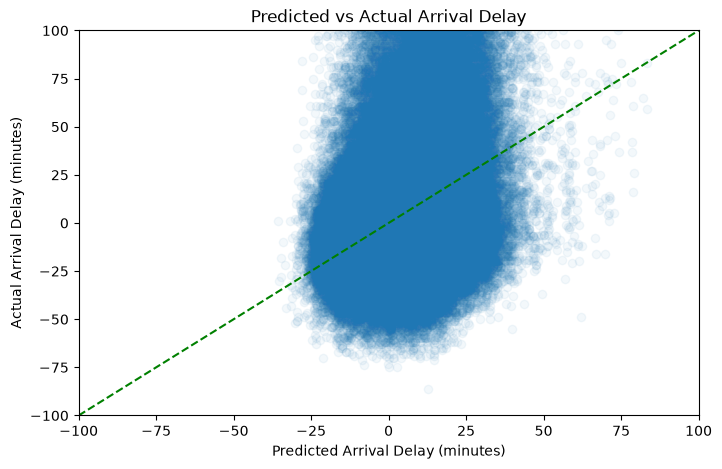

In [58]:
# Compare predicted and actual arrival delays

predicted = model2_fit.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(
    predicted,
    y_model2,
    alpha=0.05
)

plt.xlabel("Predicted Arrival Delay (minutes)")
plt.ylabel("Actual Arrival Delay (minutes)")
plt.title("Predicted vs Actual Arrival Delay")
plt.xlim(-100, 100)
plt.ylim(-100, 100)
plt.axline((0, 0), slope=1, color='Green', linestyle='--')

plt.show()

The model captures general delay patterns, however, substantial variation remains unexplained. 

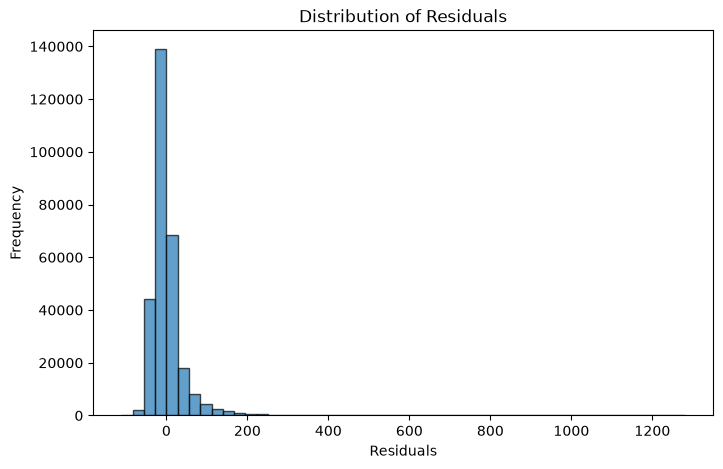

In [59]:
# Distribution of residuals

plt.figure(figsize=(8,5))

plt.hist(
    model2_fit.resid,
    bins=50,
    edgecolor='k',
    alpha=0.7
)
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

The distribution of residuals is right skewed which sugguests unusually large delays are still difficult to explain with the variables included in the model.

In [60]:
# Set reference categories

model1_comparison_data["season"] = pd.Categorical(
    model1_comparison_data["season"],   
    categories=["Winter", "Spring", "Summer", "Fall"]   
)

model1_comparison_data["carrier"] = pd.Categorical(
    model1_comparison_data["carrier"],  
    categories = [
            "AA", "AS", "B6", "DL", "EV", "F9", "FL", "HA", "MQ", "OO", "UA", "US", "VX", "WN", "YV", "9E"
            ]   
)

model1_comparison_data["origin"] = pd.Categorical(
    model1_comparison_data["origin"],   
    categories=["JFK", "LGA", "EWR"]
)



In [61]:
# create dummy variables

model1_comparison_data = pd.get_dummies(model1_comparison_data, columns=['season', 'carrier', 'origin'], drop_first=True, dtype=int)

In [62]:
# Run Model 1 on the same sample as Model 2

y_model1 = model1_comparison_data['arr_delay']
X_model1 = model1_comparison_data.drop(
    columns=['arr_delay']
)
x_model1 = sm.add_constant(X_model1)

model1_comparison = sm.OLS(y_model1, x_model1).fit()



In [63]:
comparison = pd.DataFrame({
    "Metric": ["R-squared", "Adj. R-squared", "AIC", "BIC"],
    "Model 1": [
        round(model1_comparison.rsquared, 4),
        round(model1_comparison.rsquared_adj, 4),
        round(model1_comparison.aic, 4),
        round(model1_comparison.bic, 4)
    ],
    "Model 2": [
        round(model2_fit.rsquared, 4),
        round(model2_fit.rsquared_adj, 4),
        round(model2_fit.aic, 4),
        round(model2_fit.bic, 4)
    ]
})

print(comparison)

           Metric       Model 1       Model 2
0       R-squared  5.400000e-02  7.970000e-02
1  Adj. R-squared  5.390000e-02  7.960000e-02
2             AIC  2.985835e+06  2.977827e+06
3             BIC  2.986079e+06  2.978134e+06


Model 2 builds on model 1 through incorporating weather variables such as temperature, humidity, wind speed, precipitation, pressure, and visibility. Using the same sample size of 291,140 flights, model 2 achieved a higher r-squared, adjusted r-squared, and produced lower AIC and BIC values. This sugguests that weather conditions contribute additional explanatory power past flight scheduling and operational characteristics alone. 